# Phase 1–2 — evidence repair and verification

This is an executed engineering/diagnostic record, outside the 22-node official DAG.
It preserves old outputs, captures commands and failures, and does not infer new
scientific results from code/test completion. Historical ASR final-test was used
for selection. No new final-test inference or candidate expansion is performed.
Dataset qualification may correctly return PENDING rather than scientific eligibility.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, os, subprocess, sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
assert (ROOT / "experiments/notebooks/notebook_manifest.yaml").is_file(), ROOT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_ROOT = ROOT / "experiments/outputs/phase12_repair_260926" / STAMP
RUN_ROOT.mkdir(parents=True, exist_ok=False)
commands = []
def run(args, *, accepted=(0,), timeout=900):
    command = [sys.executable, *args]
    print("COMMAND:", subprocess.list2cmdline(command), flush=True)
    started = datetime.now(timezone.utc).isoformat()
    env = dict(os.environ, PYTHONIOENCODING="utf-8", MPLBACKEND="Agg",
               HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1")
    try:
        result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                                encoding="utf-8", errors="replace", env=env, timeout=timeout)
        print(result.stdout, end="")
        print(result.stderr, end="", file=sys.stderr)
        row = dict(command=command, started=started, exit_code=result.returncode,
                   stdout=result.stdout, stderr=result.stderr, accepted=list(accepted))
    except subprocess.TimeoutExpired as exc:
        def text(value):
            return value.decode("utf-8", "replace") if isinstance(value, bytes) else (value or "")
        row = dict(command=command, started=started, exit_code="timeout",
                   stdout=text(exc.stdout), stderr=text(exc.stderr), accepted=list(accepted))
        print(row["stdout"], row["stderr"])
    row["accepted_outcome"] = row["exit_code"] in accepted
    commands.append(row)
    (RUN_ROOT / "commands.json").write_text(json.dumps(commands, indent=2), encoding="utf-8")
    print("EXIT:", row["exit_code"], "EXPECTED:", row["accepted_outcome"], flush=True)
    return row
print("Fresh artifact root:", RUN_ROOT)
print("Python:", sys.version)


Fresh artifact root: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z
Python: 3.11.1 (tags/v3.11.1:a7a450f, Dec  6 2022, 19:58:39) [MSC v.1934 64 bit (AMD64)]


## Regenerate task notebooks and run focused regression tests

In [2]:
run(["-m", "experiments.scripts.generate_refactored_notebook"])
run(["-m", "compileall", "-q", "experiments/scripts/artifact_enrichment.py",
     "experiments/scripts/notebook_results.py", "experiments/scripts/dataset_freeze_evidence.py",
     "experiments/scripts/benchmark_artifacts.py", "experiments/scripts/stage_benchmark_helpers.py",
     "experiments/scripts/profile_dataset.py", "experiments/scripts/phase2_freeze_tedlium.py",
     "experiments/scripts/phase2_freeze_iiit_cvid.py", "experiments/scripts/emit_audio_modality_figures.py",
     "experiments/scripts/emit_iiit_cvid_image_figures.py", "experiments/evaluation/asr_selection_scoring.py",
     "benchmarks/scripts/execute_all_notebooks.py", "benchmarks/scripts/run_asr_model_benchmark.py",
     "benchmarks/scripts/run_asr_preprocessing_ablation.py"])
tests = [
    "test_artifact_enrichment.py", "test_notebook_generator.py", "test_notebook_executor.py", "test_notebook_results.py",
    "test_asr_selection_scoring.py", "test_dataset_freeze_evidence.py",
    "test_dataset_contracts.py", "test_d2_freeze_pipeline.py", "test_phase2_tedlium_d2.py",
    "test_unlock_iiit_cvid_d2.py", "test_audio_modality_figures.py",
    "test_endpoint_eligibility.py", "test_group02_group07_reconciliation.py",
    "test_phase1_all_runners_exist.py", "test_phase1_stage_smoke_runners.py",
    "test_phase1_priority_runners.py", "test_dataset_qualification_runtime.py",
]
run(["-m", "pytest", "-q", *["tests/" + name for name in tests]], timeout=900)


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m experiments.scripts.generate_refactored_notebook


[OK] 0 notebook(s) generated
EXIT: 0 EXPECTED: True


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m compileall -q experiments/scripts/artifact_enrichment.py experiments/scripts/notebook_results.py experiments/scripts/dataset_freeze_evidence.py experiments/scripts/benchmark_artifacts.py experiments/scripts/stage_benchmark_helpers.py experiments/scripts/profile_dataset.py experiments/scripts/phase2_freeze_tedlium.py experiments/scripts/phase2_freeze_iiit_cvid.py experiments/scripts/emit_audio_modality_figures.py experiments/scripts/emit_iiit_cvid_image_figures.py experiments/evaluation/asr_selection_scoring.py benchmarks/scripts/execute_all_notebooks.py benchmarks/scripts/run_asr_model_benchmark.py benchmarks/scripts/run_asr_preprocessing_ablation.py


EXIT: 0 EXPECTED: True


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m pytest -q tests/test_artifact_enrichment.py tests/test_notebook_generator.py tests/test_notebook_executor.py tests/test_notebook_results.py tests/test_asr_selection_scoring.py tests/test_dataset_freeze_evidence.py tests/test_dataset_contracts.py tests/test_d2_freeze_pipeline.py tests/test_phase2_tedlium_d2.py tests/test_unlock_iiit_cvid_d2.py tests/test_audio_modality_figures.py tests/test_endpoint_eligibility.py tests/test_group02_group07_reconciliation.py tests/test_phase1_all_runners_exist.py tests/test_phase1_stage_smoke_runners.py tests/test_phase1_priority_runners.py tests/test_dataset_qualification_runtime.py


........................................................................ [ 30%]
........................................................................ [ 61%]
........................................................................ [ 92%]
.................                                                        [100%]
233 passed in 113.54s (0:01:53)
EXIT: 0 EXPECTED: True


{'command': ['C:\\Users\\hung\\AppData\\Local\\Programs\\Python\\Python311\\python.exe',
  '-m',
  'pytest',
  '-q',
  'tests/test_artifact_enrichment.py',
  'tests/test_notebook_generator.py',
  'tests/test_notebook_executor.py',
  'tests/test_notebook_results.py',
  'tests/test_asr_selection_scoring.py',
  'tests/test_dataset_freeze_evidence.py',
  'tests/test_dataset_contracts.py',
  'tests/test_d2_freeze_pipeline.py',
  'tests/test_phase2_tedlium_d2.py',
  'tests/test_unlock_iiit_cvid_d2.py',
  'tests/test_audio_modality_figures.py',
  'tests/test_endpoint_eligibility.py',
  'tests/test_group02_group07_reconciliation.py',
  'tests/test_phase1_all_runners_exist.py',
  'tests/test_phase1_stage_smoke_runners.py',
  'tests/test_phase1_priority_runners.py',
  'tests/test_dataset_qualification_runtime.py'],
 'started': '2026-09-26T09:41:56.590111+00:00',
 'exit_code': 0,
 'stdout': '........................................................................ [ 30%]\n.........................

## Rebuild measured dataset diagnostics in fresh roots
Exit 3 means unresolved scientific gates; it is recorded as PENDING, never PASS.

In [3]:
datasets = {"tedlium3": ("phase2_freeze_tedlium", "emit_audio_modality_figures"),
            "iiit_cvid": ("phase2_freeze_iiit_cvid", "emit_iiit_cvid_image_figures")}
dataset_runs = {}
for dataset, (driver, emitter) in datasets.items():
    root = RUN_ROOT / dataset
    result = run(["-m", "experiments.scripts." + driver, "--artifact-root", str(root)], accepted=(0, 3))
    dataset_runs[dataset] = result
    if result["accepted_outcome"] and (root / "official/full/payloads/dataset.figure_manifest.json").is_file():
        run(["-m", "experiments.scripts." + emitter, "--artifact-root", str(root)])


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m experiments.scripts.phase2_freeze_tedlium --artifact-root C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\tedlium3


[OK] dataset profile: 1 dataset(s), 20 real file(s), 0 D2-eligible frozen dataset(s)
[PENDING] No scientifically eligible freeze; diagnostic artifacts retained
EXIT: 3 EXPECTED: True


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m experiments.scripts.emit_audio_modality_figures --artifact-root C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\tedlium3


PENDING/BLOCKED: profile_dataset returned 3; inspect diagnostic artifacts


Emitted 6 audio figures under C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\tedlium3\official\full\figures\audio
  source_artifact: dataset.statistics
  source_table_sha256: 6e582ac4536f584bc21ebcefa85c1e7fa400270fbd2ce80a341ba0e7e39beaf0
  audio_statistics_sha256: a60b569cdd976d357bb515eaeb2e1f09b83175500b5a06b0a53a2eef361a4480
  unit_profile_sha256: df66254665e0a4dcb37376b434466ecf3df1a779ae03a1e5b757e5d237976b5e
  n (measured units): 20
  figure_manifest entries: 14 total
    audio_duration_ecdf                     32.2 KiB
    audio_sample_rate_distribution          49.7 KiB
    audio_channel_layout                    37.6 KiB
    audio_peak_rms_distribution             41.2 KiB
    audio_speech_ratio_distribution         34.7 KiB
    audio_duration_vs_size                  55.3 KiB
EXIT: 0 EXPECTED: True


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m experiments.scripts.phase2_freeze_iiit_cvid --artifact-root C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\iiit_cvid


[OK] dataset profile: 1 dataset(s), 2115 real file(s), 0 D2-eligible frozen dataset(s)
[PENDING] No scientifically eligible freeze; diagnostic artifacts retained
EXIT: 3 EXPECTED: True


COMMAND: C:\Users\hung\AppData\Local\Programs\Python\Python311\python.exe -m experiments.scripts.emit_iiit_cvid_image_figures --artifact-root C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\iiit_cvid


PENDING/BLOCKED: profile_dataset returned 3; inspect diagnostic artifacts


Emitted 4 image figures under C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\phase12_repair_260926\20260926T094154516917Z\iiit_cvid\official\full\figures
  source_artifact: dataset.statistics
  source_table_sha256: 5b6563170875216edac5ac404232a909b5d8ec12ec96f1867d3c21fa11ef4c9c
  image_geometry_sha256: c884d5a45486e28113938f477a8a291b34d67baec9fcc22fe4a285cad89962ac
  n (profiled units): 2115  split_unit_counts: {'final_test': 1755, 'validation': 360}
  figure_manifest entries: 12 total
EXIT: 0 EXPECTED: True


## Validate receipts and render current tables/figures
Ineligible data must remain blocked for model selection.

tedlium3 receipt errors: []
EXPECTED SCIENTIFIC BLOCK: ['dataset.frozen_manifest: no scientifically eligible frozen units']


### Saved evidence — `00c_dataset_eda_and_freeze`

Namespace: `official/full`. Tables show artifact contents; execution alone does not establish scientific eligibility.

#### `dataset.profile`

1 rows; displaying at most 20. Run `6afc1d03-4cf4-451a-809c-faa5803750a6`; SHA-256 `bdf4ac52ca86cbad340e34b860232c77b3734eaaa768ce129c50a11beb038882`.

,dataset_id,source,acquisition_level,profile,raw_file_count,eligible_file_count,excluded_file_count,unresolved_file_count,selected_bytes,selection_policy,ground_truth_status
0,tedlium3,local_huggingface_saved_arrow,D2,full,20,20,0,0,5509872,deterministic_sha256_rank_balanced_validation_...,released_manual_transcripts_CC_BY_NC_ND_3.0


#### `dataset.statistics`

... (19 outputs left out)

**PENDING — split_comparison**: universal EDA plot not rendered; not scientific figure evidence.

**PENDING — source_overlap**: universal EDA plot not rendered; not scientific figure evidence.

**PENDING — duplicate_matrix**: universal EDA plot not rendered; not scientific figure evidence.

**tedlium3 — audio_duration_ecdf**, n=20

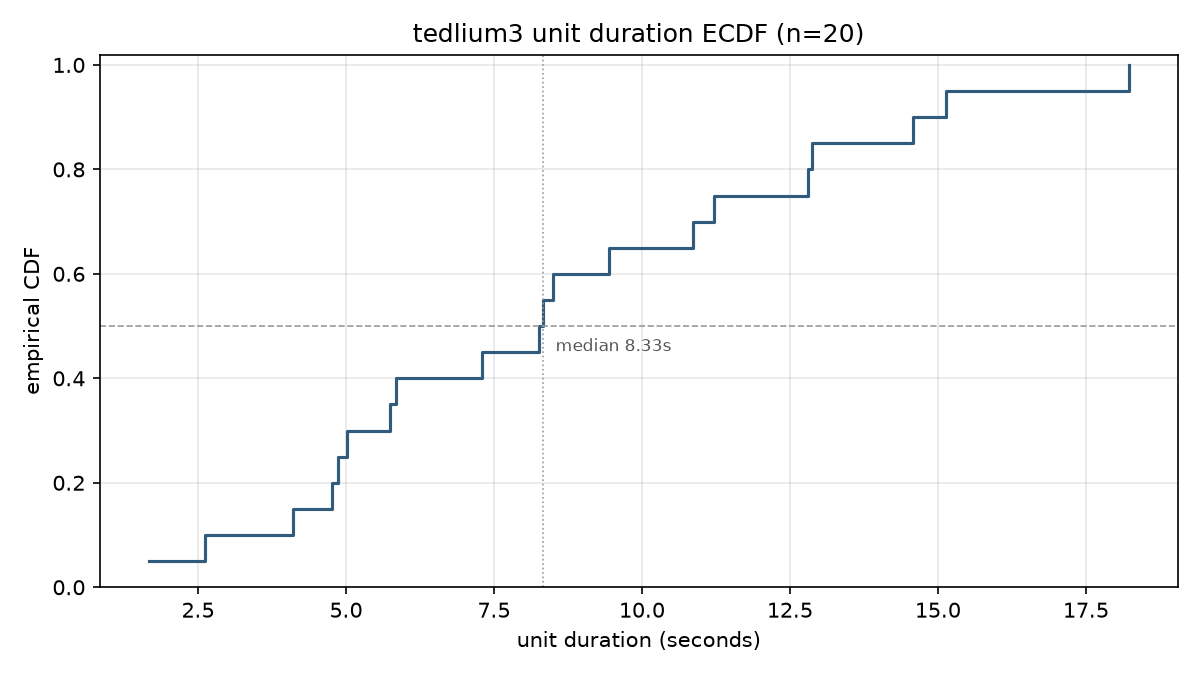

**tedlium3 — audio_sample_rate_distribution**, n=20

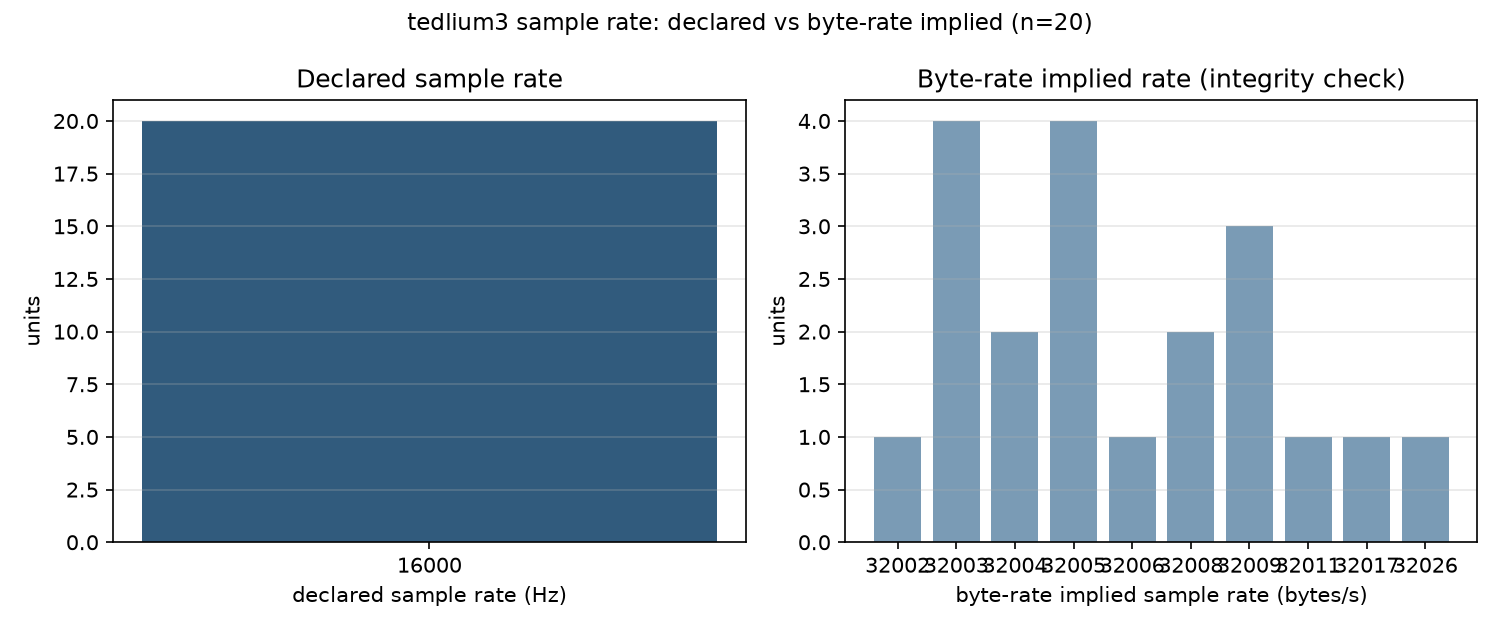

**tedlium3 — audio_channel_layout**, n=20

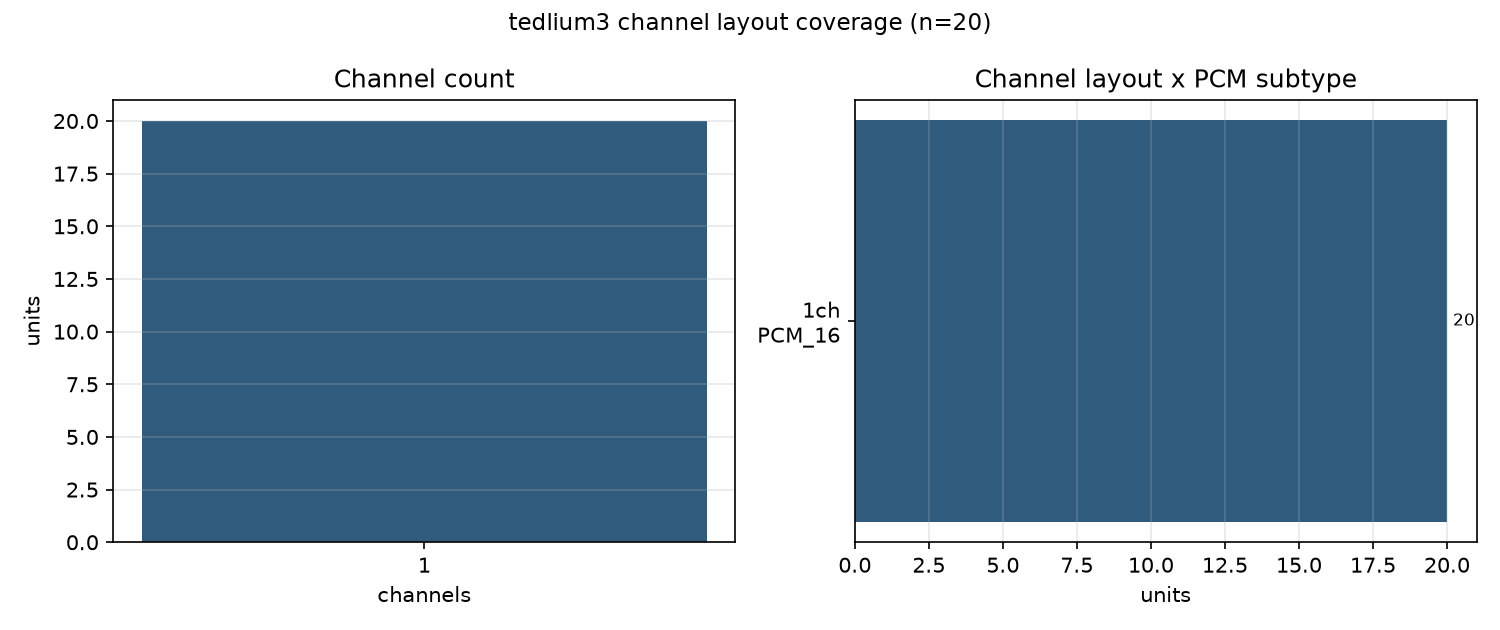

**tedlium3 — audio_peak_rms_distribution**, n=20

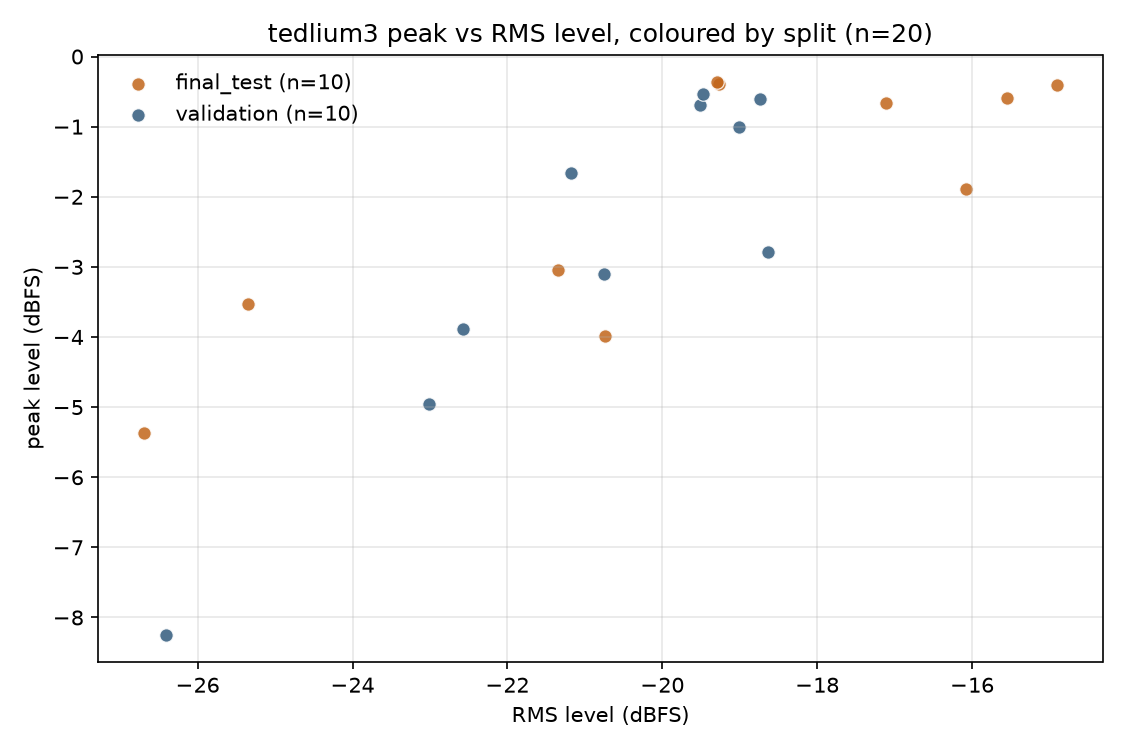

**tedlium3 — audio_speech_ratio_distribution**, n=20

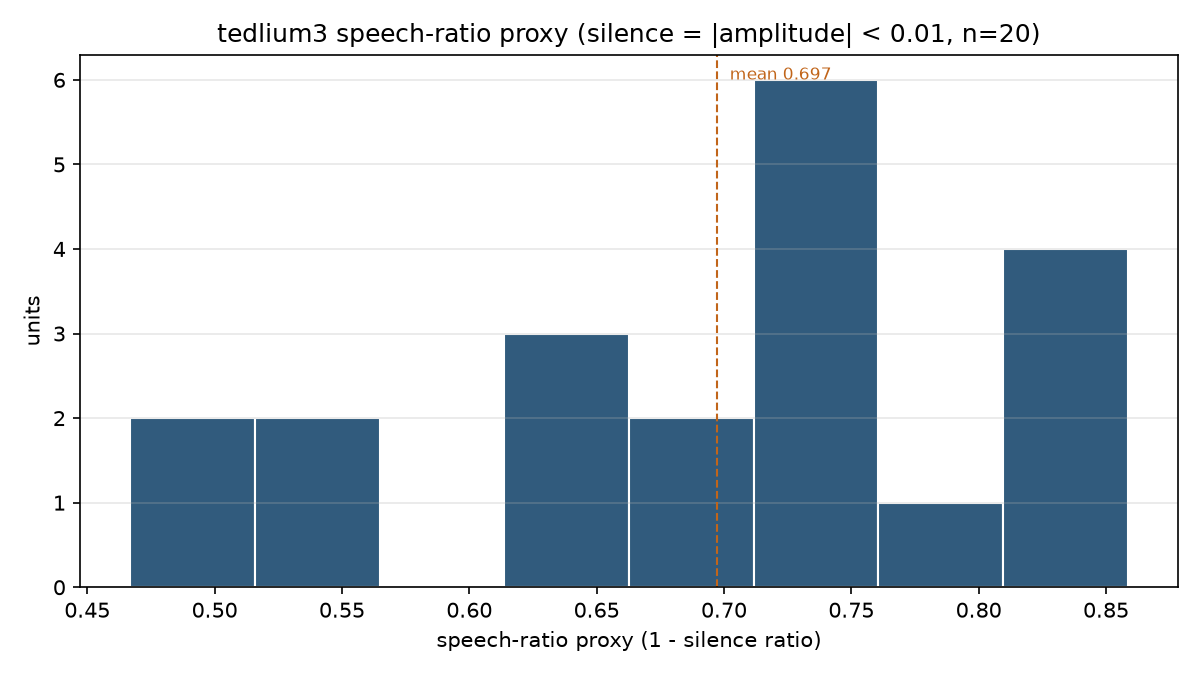

**tedlium3 — audio_duration_vs_size**, n=20

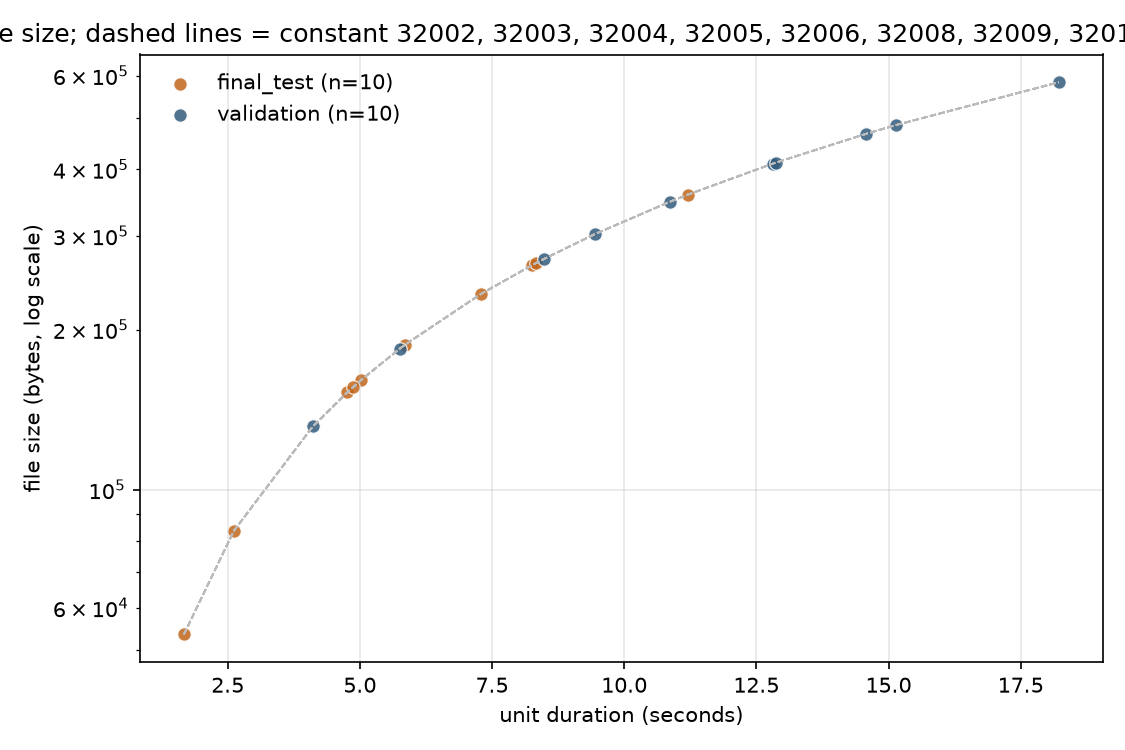

iiit_cvid receipt errors: []
EXPECTED SCIENTIFIC BLOCK: ['dataset.frozen_manifest: no scientifically eligible frozen units']


### Saved evidence — `00c_dataset_eda_and_freeze`

Namespace: `official/full`. Tables show artifact contents; execution alone does not establish scientific eligibility.

#### `dataset.profile`

1 rows; displaying at most 20. Run `1329e0d8-b41c-4bfe-a8e9-3c9528d7572e`; SHA-256 `be35d38b5755a7221ac968c402b196a99291812f924aa6f1c9709d0c95747785`.

,dataset_id,source,acquisition_level,profile,raw_file_count,eligible_file_count,excluded_file_count,unresolved_file_count,selected_bytes,selection_policy,ground_truth_status
0,iiit_cvid,local_extracted_zip,D2,full,2115,2115,0,0,540960433,final_test=complete_official_test_split_frames...,released_manual_frame_transcriptions_academic_...


#### `dataset.statistics`

... (19 outputs left out)

**PENDING — split_comparison**: universal EDA plot not rendered; not scientific figure evidence.

**PENDING — source_overlap**: universal EDA plot not rendered; not scientific figure evidence.

**PENDING — duplicate_matrix**: universal EDA plot not rendered; not scientific figure evidence.

**iiit_cvid — image_resolution_distribution**, n=2115

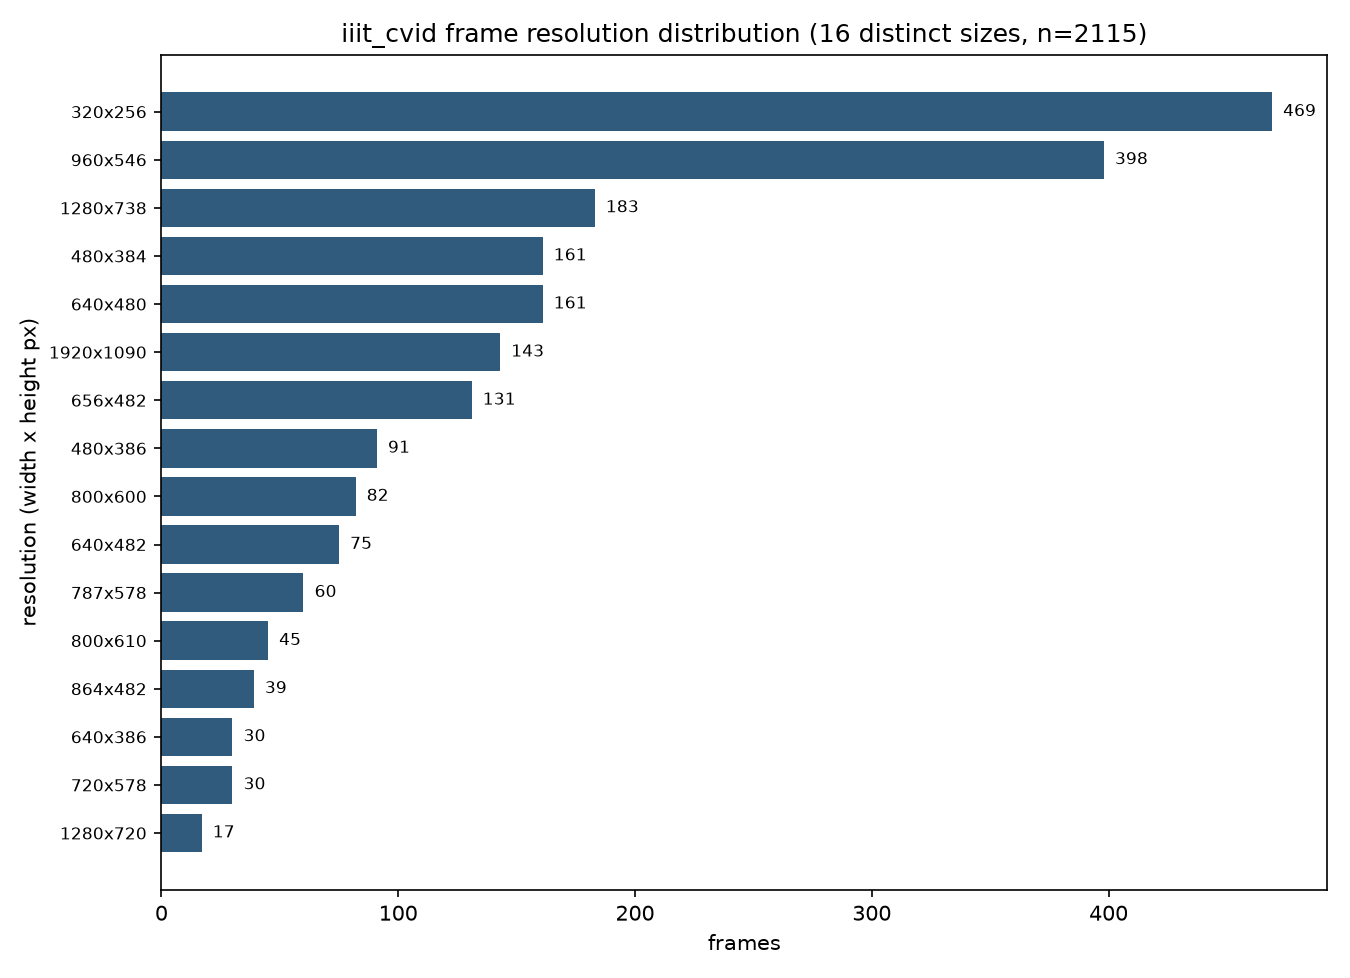

**iiit_cvid — image_aspect_ratio_distribution**, n=2115

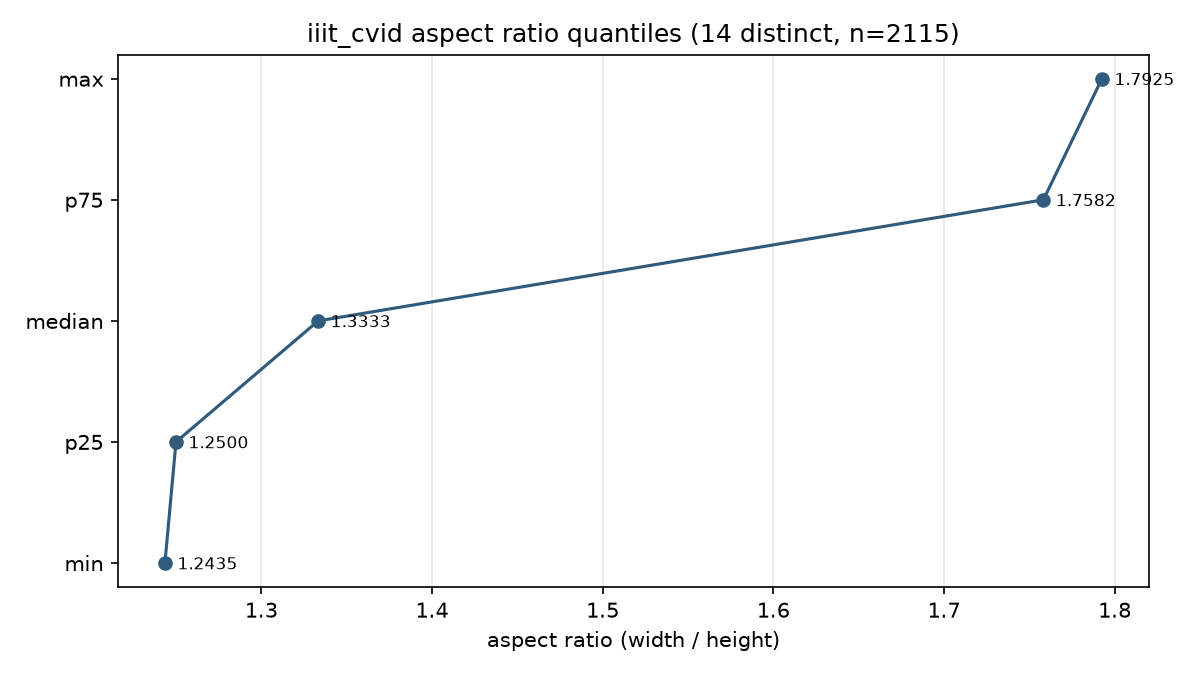

**iiit_cvid — image_mode_histogram**, n=2115

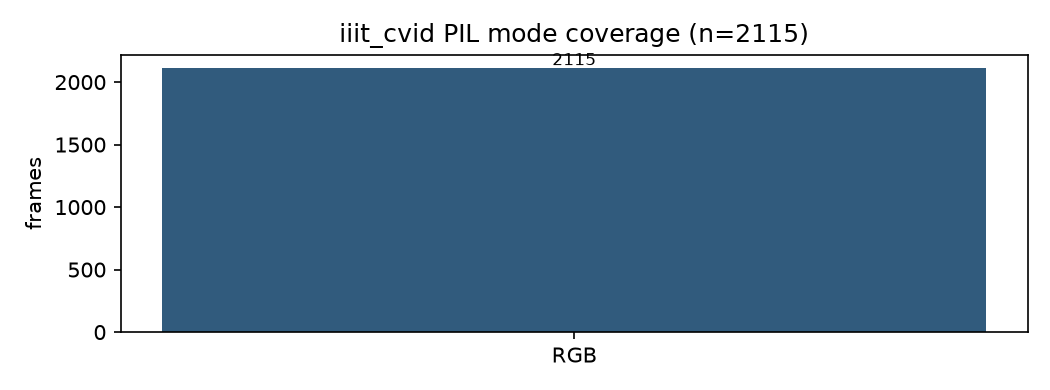

**iiit_cvid — image_text_line_density**, n=2115

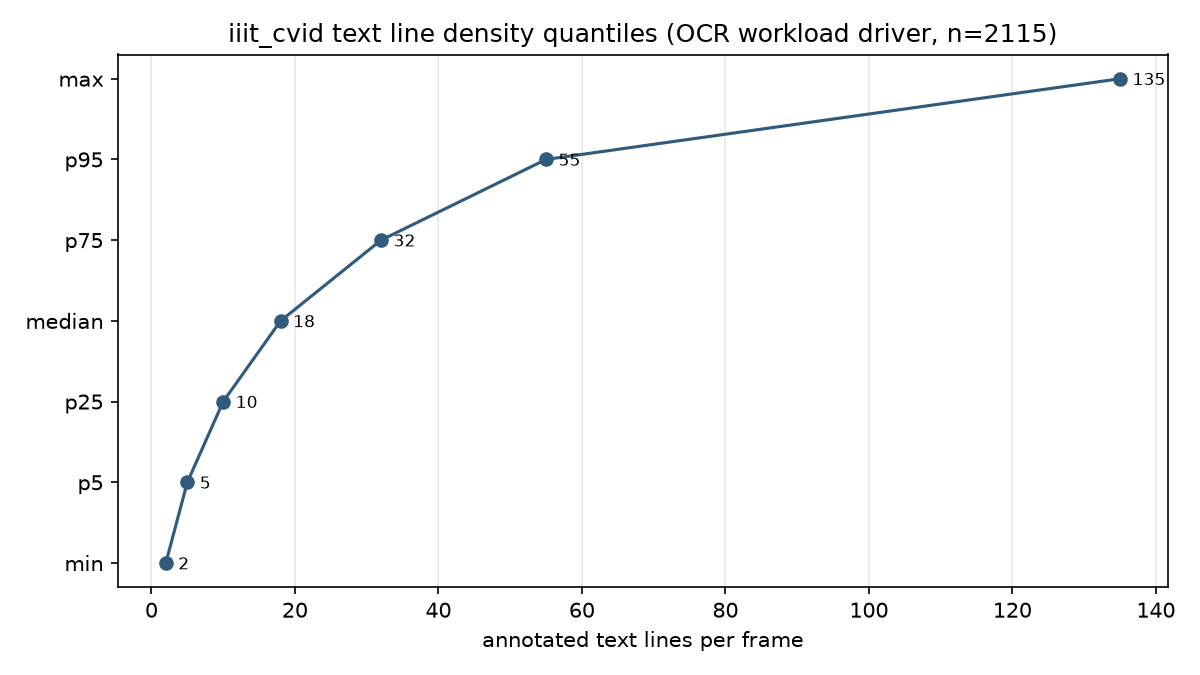

,dataset,valid_receipts,scientific_eligible
0,tedlium3,18,False
1,iiit_cvid,18,False


In [4]:
from experiments.scripts.benchmark_artifacts import RunnerContext, read_json_artifact, sha256_file
from experiments.scripts.notebook_results import render_artifacts
from benchmarks.scripts.execute_all_notebooks import _validate_artifacts, validate_required_artifacts

receipt_checks = []
for dataset in datasets:
    root = RUN_ROOT / dataset
    namespace = root / "official/full"
    receipt_path = namespace / "dataset.figure_manifest.receipt.json"
    if not receipt_path.is_file():
        print(dataset, "BLOCKED before characterization; see driver output")
        continue
    receipt = json.loads(receipt_path.read_text())
    context = RunnerContext("full", "official", "real", root, receipt["producer_notebook_id"],
                            receipt["run_id"], receipt["source_sha256"], receipt["config_sha256"],
                            receipt["dependency_state_sha256"])
    ids = [p.name.removesuffix(".receipt.json") for p in namespace.glob("*.receipt.json")]
    errors = _validate_artifacts(ids, 1, root, "full", "official")
    for artifact_id in ids:
        if artifact_id != "dataset.eda_report":
            read_json_artifact(context, artifact_id)
    print(dataset, "receipt errors:", errors)
    assert not errors, errors
    frozen = read_json_artifact(context, "dataset.frozen_manifest")["records"]
    assert all(r["scientific_selection_eligible"] is False for r in frozen)
    gate = validate_required_artifacts({"requires": ["dataset.frozen_manifest"],
                                       "expected_schema_version": 1}, root, "full", "official")
    assert any("no scientifically eligible" in error for error in gate), gate
    print("EXPECTED SCIENTIFIC BLOCK:", gate)
    receipt_checks.append(dict(dataset=dataset, valid_receipts=len(ids), scientific_eligible=False))
    render_artifacts(context, ["dataset.profile", "dataset.statistics", "dataset.split_statistics",
                              "dataset.leakage_audit", "dataset.endpoint_matrix", "dataset.figure_manifest"])
display(pd.DataFrame(receipt_checks))


## Historical ASR — diagnostic re-scoring only
These are loaded predictions, not new inference. Both old splits were used for selection; no held-out accuracy claim or winner is produced. New scorer versions are intentionally not directly comparable to old WER/CER.

In [5]:
from experiments.evaluation.asr_selection_scoring import score_asr_pairs, scoring_metadata
old = ROOT / "experiments/outputs/phase2_tedlium_d2/official/full/payloads"
historical = json.loads((old / "asr.raw_predictions.json").read_text())["records"]
frozen = json.loads((old / "dataset.frozen_manifest.json").read_text())["records"][0]["unit_records"]
units = {row["unit_id"]: row for row in frozen}
rows = []
for candidate in sorted({r["candidate"] for r in historical}):
    for split in ("validation", "final_test"):
        subset = [r for r in historical if r["candidate"] == candidate and units[r["unit_id"]]["split"] == split]
        scores = score_asr_pairs([(r["predictions"]["reference"], r["predictions"]["hypothesis"]) for r in subset])
        rows.append(dict(candidate=candidate, historical_split=split, evidence="diagnostic_rescore_contaminated_holdout", **scores))
print("Scorer:", scoring_metadata())
display(pd.DataFrame(rows))
(RUN_ROOT / "historical-asr-diagnostic-rescore.json").write_text(
    json.dumps(dict(scoring=scoring_metadata(), records=rows), indent=2), encoding="utf-8")


Scorer: {'normalizer': 'english-asr-nfkc-apostrophe-us-v1', 'scorer': 'per-unit-levenshtein-micro-v1', 'cer_policy': 'normalized_characters_including_spaces'}


,candidate,historical_split,evidence,wer,cer,word_errors,reference_words,character_errors,reference_characters,unit_count
0,faster-whisper-base.en,validation,diagnostic_rescore_contaminated_holdout,0.041420,0.027451,14,338,49,1785,10
1,faster-whisper-base.en,final_test,diagnostic_rescore_contaminated_holdout,0.059524,0.028743,10,168,24,835,10
2,faster-whisper-tiny.en,validation,diagnostic_rescore_contaminated_holdout,0.047337,0.030812,16,338,55,1785,10
3,faster-whisper-tiny.en,final_test,diagnostic_rescore_contaminated_holdout,0.041667,0.026347,7,168,22,835,10


1687

## Preservation and outcome

In [6]:
baseline = ROOT.parent / "plans/260926-phase12-evidence-repair/historical-before.json"
before = json.loads(baseline.read_text(encoding="utf-8-sig"))
changed = [row["path"] for row in before if sha256_file(Path(row["path"])).lower() != row["sha256"].lower()]
print("Historical files checked:", len(before), "changed:", changed)
assert not changed, "Historical evidence must remain unchanged"
display(pd.DataFrame([{k: row[k] for k in ("command", "exit_code", "accepted_outcome")} for row in commands]))
failures = [row for row in commands if not row["accepted_outcome"]]
print("Unexpected command failures:", len(failures))
print("Scientific gates still pending: near-duplicate adjudication, independent ASR holdout, complete endpoint GT coverage, full DAG/equivalence.")
assert not failures, "See captured command output; engineering verification is not complete"
assert len(receipt_checks) == 2, "Both dataset diagnostic bundles must be validated"


Historical files checked: 151 changed: []


,command,exit_code,accepted_outcome
0,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
1,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
2,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
3,[C:\Users\hung\AppData\Local\Programs\Python\P...,3,True
4,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
5,[C:\Users\hung\AppData\Local\Programs\Python\P...,3,True
6,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True


Unexpected command failures: 0
Scientific gates still pending: near-duplicate adjudication, independent ASR holdout, complete endpoint GT coverage, full DAG/equivalence.
